# HMD Raga Feature Extraction Pipeline
Extracts **Spectrogram**, **Log-Mel Spectrogram**, and **Cochleagram** features from the Hindustani Music Dataset (HMD), with raga labels resolved via uuid folder lookup.

Structure assumed:
```
root_dir/<uuid>/<Singer>/<Raag_Folder>/<audio_file>
```
Output: 3 pickle files, each holding `(feature_array, raga_label, file_path)` per song.

## 1. Install & Import

In [1]:
!pip install librosa gammatone -q

In [2]:
import os
import pickle
import numpy as np
import librosa
from gammatone import gtgram
from tqdm.notebook import tqdm

## 2. Config

In [3]:
# ---------------------------------------------------------------------------
# Config (according to Thesis)
# ---------------------------------------------------------------------------
SR = 16000            # sample rate to resample audio to
N_FFT = 512            # FFT window size
HOP_LENGTH = 320       # hop size (10 ms at 16kHz)
N_MELS = 64             # number of mel bands
GT_WIN_TIME = 0.025     # gammatone window (25 ms)
GT_HOP_TIME = 0.010     # gammatone hop (10 ms)
GT_CHANNELS = 128       # number of gammatone filters
GT_F_MIN = 50           # lowest center frequency (Hz)

AUDIO_EXTS = (".mp3", ".wav")
UUID_LEN = 36           # standard uuid length, used to strip Kaggle duplicate suffixes like ' 2'

ROOT_DIR = "/kaggle/input/datasets/mishbhaul/indian-raga-dataset/RagaDataset/Hindustani/audio"
OUTPUT_DIR = "/kaggle/working/features_with_labels"


## 3. Raga ID Mapping
Paste your full `uuid -> raga_name` dictionary here (as seen in your dataset's mapping file/screenshot).

In [4]:
legend = {"6345e8fe-7061-4bdc-842c-dcfd4a379820": "A\u1e6d\u0101na", "98d46d9e-5100-4f24-bcd4-d0f95966c7cb": "Sindhubhairavi", "5ce23030-f71d-4f5d-9d76-f91c2c182392": "Dhany\u0101si", "cda9cbe9-c1aa-42bb-8b4c-e9dfc8af133c": "N\u0101\u1e6dakurinji", "bf4662d4-25c3-4cad-9249-4de2dc513c06": "Kaly\u0101\u1e47i", "1e7de02f-e77f-405a-a033-f31117aaf955": "Bhairav", "4ce0b18d-f4df-41cf-9b40-9166199506b4": "R\u012btigau\u1e37a", "64e5fb9e-5569-4e80-8e6c-f543af9469c7": "M\u0101lkauns", "0b3bbf97-0ec3-41da-add4-722d87329ec3": "Madhukauns", "a99e07d5-20a0-467b-8dcd-aa5a095177fd": "Lalit", "39821826-3327-41d7-9cd5-e22fe7b08360": "M\u014dhana\u1e41", "18b1acb9-dff6-47ec-873a-b2086c8d268d": "Madhyam\u0101vati", "c6b5f8d9-ebb4-46af-a020-6646fce2c77d": "S\u0101ma", "595de771-fcc2-414c-9df6-ae4ffd898549": "Hamsadhv\u0101ni", "7591faad-e68a-4550-b675-8082842c6056": "B\u0101g\u0113\u015br\u012b", "b6989a44-e85d-43cf-8b95-2eae5dcd28a2": "P\u016brv\u012bka\u1e37y\u0101\u1e47i", "db085e26-665d-4f4c-a2a5-95251c22b69e": "P\u016brv\u012bka\u1e37y\u0101\u1e47i", "e8a0bf54-13c6-4a09-922a-bfc744ddf38a": "Var\u0101\u1e37i", "3af5a361-923a-465d-864d-9c7ba0c04a47": "Sencuru\u1e6d\u1e6di", "e771a74d-545d-41d5-816b-43403a818b0c": "Bh\u016bp", "62b79291-73b0-4c77-a353-0f8bc6ed8362": "D\u0113\u015b", "e18fcaa7-1f9c-4f09-b627-0687481f4ec7": "\u0100nandabhairavi", "a4ec6633-1050-4207-8313-b017194c8fa0": "Kam\u0101s", "48b37bed-e847-4882-8a01-5c721e07f07d": "Yaman kaly\u0101\u1e47", "2165542c-45da-4301-af82-c2e7ddbe4768": "Bilahari", "f7fddfc0-8c1d-4dd2-90d5-5d51a99d61f8": "R\u0101g\u0113\u015br\u012b", "3eb7ba30-4b94-432e-9618-875ee57e01ab": "M\u0101rv\u0101", "1b05a564-059f-445b-b325-cf26318367e3": "Miy\u0101n malh\u0101r", "f6432fec-e9c2-4b09-9e73-c46086cbd8ea": "Ahira bhairav", "09c179f3-8b19-4792-a852-e9fa0090e409": "K\u0101pi", "54c4214c-05b9-4acc-8f77-6d5786e43a2e": "M\u0101r\u016bbih\u0101g", "ddff55ae-20f6-4d7d-ba9e-a6c10eeebd41": "Yadukula k\u0101\u1e41b\u014dji", "a9413dff-91d1-4e29-ad92-c04019dce5b8": "T\u014d\u1e0di", "defad4cc-48aa-4372-a31a-c43624930713": "D\u0113vag\u0101ndh\u0101ri", "a47e9d22-847a-46e8-b589-2a3537789f5f": "S\u0101v\u0113ri", "978f4c3c-6a12-43fd-8427-c414ee17b252": "Mukh\u0101ri", "40dbe1db-858f-4366-bef8-9076eb67340d": "\u015auddh s\u0101ra\u1e45g", "118401e7-8de8-4d81-9d8e-8070889e3fa8": "Darb\u0101ri", "9cedca68-4a9d-4170-bec3-0d1db1ff730e": "M\u0101y\u0101m\u0101\u1e37avagau\u1e37a", "839bb6b4-1577-4a78-9e5d-4906c6453274": "Sura\u1e6di", "a7d98897-e2fe-4d75-b9dc-e5b4dc88e1c6": "Bih\u0101g", "6f13484e-6fdd-402d-baf3-3835835454d0": "T\u014d\u1e0d\u012b", "42dd0ccb-f92a-4622-ae5d-a3be571b4939": "\u015ar\u012branjani", "2ed9379f-14c9-49af-8e4d-f9b63e96801f": "Alahaiy\u0101 bil\u0101val", "b143adaa-f1a6-4de4-8985-a5bd35e96279": "Bair\u0101gi", "700e1d92-7094-4c21-8a3b-d7b60c550edf": "Beh\u0101g", "a9ee554f-f146-43e9-b2d0-9bb31fd4b57d": "K\u0113d\u0101r", "0277eae5-3411-4b22-9fa8-1b347e7528d1": "\u1e62anmukhapriya", "df85a0a5-b1a8-42f1-a87b-3d7c7ee33fb4": "K\u0113d\u0101ragau\u1e37a", "ba3242d0-8d40-4d93-865e-d2e2497ea2a8": "Gau\u1e0d malh\u0101r", "46997b02-f09c-4969-8138-4e1861f61967": "\u015ar\u012b", "290674e0-d94c-41c1-ad99-f65fa22a1447": "Madhuvanti", "85ccf631-4cdf-4f6c-a841-0edfcf4255d1": "K\u0101mavardani", "a2f9f182-0ceb-4531-b286-b840b47a54b8": "\u015aankar\u0101bhara\u1e47a\u1e41", "e5c4d94a-b34a-42ef-acd7-f235612350e4": "Gau\u1e37a", "fa28470c-d413-44c7-94da-181f530cbfdd": "Puriy\u0101 dhana\u015br\u012b", "dd59147d-8775-44ff-a36b-0d9f15b31319": "Bil\u0101sakh\u0101n\u012b t\u014d\u1e0d\u012b", "bdd80890-44f1-4a93-8d93-06a418781f97": "\u015ar\u012b", "d9c603fa-875f-4b84-b851-c6a345427898": "\u0100bh\u014dg\u012b", "123b09bd-9901-4e64-a65a-10b02c9e0597": "Bhairavi", "f0866e71-33b2-47db-ab75-0808c41f2401": "K\u0101\u1e41bh\u014dji", "f972db4d-5d16-4f9a-9841-f313e1601aaa": "Karaharapriya", "ecd04ceb-b46c-47fc-9045-84ac9160e527": "Basant", "93c73081-bdf8-4eca-b325-d736b71e9b4b": "Kham\u0101j", "b08475a2-1049-433a-be8f-105bf14718fb": "Harik\u0101mbh\u014dji", "aa5f376f-06cd-4a69-9cc9-b1077104e0b0": "B\u0113ga\u1e0da", "9ebeb536-30a7-403f-8042-f7c1445c4b87": "N\u0101\u1e6da", "50bd048f-4482-4c5b-850c-9ad5e5ec46f1": "Huss\u0113n\u012b", "993d6cf6-dc89-4d23-9a9f-8eeed1524872": "Sah\u0101n\u0101", "063ea5a0-23b1-4bb5-8537-3d924fe8ebb3": "J\u014dg", "9a071e54-3eed-48b2-83a3-1a3fd683b8e0": "K\u0101na\u1e0da"}

In [5]:
# creating a map for the ragas available to us in the dataset

keys = os.listdir(ROOT_DIR)

mapping = dict()
for key in keys:
    clean_key = key[:36].strip().lower()
    for uuid in legend.keys():
        if uuid.strip().lower() == clean_key:
            mapping[key] = legend[uuid]
            break

print(f"Mapped {len(mapping)} out of {len(keys)} folders")
mapping

Mapped 31 out of 31 folders


{'f7fddfc0-8c1d-4dd2-90d5-5d51a99d61f8 2': 'Rāgēśrī',
 'f6432fec-e9c2-4b09-9e73-c46086cbd8ea': 'Ahira bhairav',
 '290674e0-d94c-41c1-ad99-f65fa22a1447': 'Madhuvanti',
 '0b3bbf97-0ec3-41da-add4-722d87329ec3': 'Madhukauns',
 'a9ee554f-f146-43e9-b2d0-9bb31fd4b57d': 'Kēdār',
 'd9c603fa-875f-4b84-b851-c6a345427898': 'Ābhōgī',
 '1e7de02f-e77f-405a-a033-f31117aaf955': 'Bhairav',
 '3eb7ba30-4b94-432e-9618-875ee57e01ab': 'Mārvā',
 '46997b02-f09c-4969-8138-4e1861f61967': 'Śrī',
 '54c4214c-05b9-4acc-8f77-6d5786e43a2e': 'Mārūbihāg',
 'a99e07d5-20a0-467b-8dcd-aa5a095177fd': 'Lalit',
 '62b79291-73b0-4c77-a353-0f8bc6ed8362': 'Dēś',
 '118401e7-8de8-4d81-9d8e-8070889e3fa8': 'Darbāri',
 '7591faad-e68a-4550-b675-8082842c6056': 'Bāgēśrī',
 '93c73081-bdf8-4eca-b325-d736b71e9b4b': 'Khamāj',
 'ba3242d0-8d40-4d93-865e-d2e2497ea2a8': 'Gauḍ malhār',
 'ecd04ceb-b46c-47fc-9045-84ac9160e527': 'Basant',
 '6f13484e-6fdd-402d-baf3-3835835454d0': 'Tōḍī',
 'fa28470c-d413-44c7-94da-181f530cbfdd': 'Puriyā dhanaśrī',
 'f7

In [6]:
id_to_raga = {
    'f7fddfc0-8c1d-4dd2-90d5-5d51a99d61f8 2': 'Rāgēśrī',
    'f6432fec-e9c2-4b09-9e73-c46086cbd8ea': 'Ahira bhairav',
    '290674e0-d94c-41c1-ad99-f65fa22a1447': 'Madhuvanti',
    '0b3bbf97-0ec3-41da-add4-722d87329ec3': 'Madhukauns',
    'a9ee554f-f146-43e9-b2d0-9bb31fd4b57d': 'Kēdār',
    'd9c603fa-875f-4b84-b851-c6a345427898': 'Ābhōgī',
    '1e7de02f-e77f-405a-a033-f31117aaf955': 'Bhairav',
    '3eb7ba30-4b94-432e-9618-875ee57e01ab': 'Mārvā',
    '46997b02-f09c-4969-8138-4e1861f61967': 'Śrī',
    '54c4214c-05b9-4acc-8f77-6d5786e43a2e': 'Mārūbihāg',
    'a99e07d5-20a0-467b-8dcd-aa5a095177fd': 'Lalit',
    '62b79291-73b0-4c77-a353-0f8bc6ed8362': 'Dēś',
    '118401e7-8de8-4d81-9d8e-8070889e3fa8': 'Darbāri',
    '7591faad-e68a-4550-b675-8082842c6056': 'Bāgēśrī',
    '93c73081-bdf8-4eca-b325-d736b71e9b4b': 'Khamāj',
    'ba3242d0-8d40-4d93-865e-d2e2497ea2a8': 'Gauḍ malhār',
    'ecd04ceb-b46c-47fc-9045-84ac9160e527': 'Basant',
    '6f13484e-6fdd-402d-baf3-3835835454d0': 'Tōḍī',
    'fa28470c-d413-44c7-94da-181f530cbfdd': 'Puriyā dhanaśrī',
    'f7fddfc0-8c1d-4dd2-90d5-5d51a99d61f8': 'Rāgēśrī',
    '40dbe1db-858f-4366-bef8-9076eb67340d': 'Śuddh sāraṅg',
    '1b05a564-059f-445b-b325-cf26318367e3': 'Miyān malhār',
    'b143adaa-f1a6-4de4-8985-a5bd35e96279': 'Bairāgi',
    '64e5fb9e-5569-4e80-8e6c-f543af9469c7': 'Mālkauns',
    '2ed9379f-14c9-49af-8e4d-f9b63e96801f': 'Alahaiyā bilāval',
    'e771a74d-545d-41d5-816b-43403a818b0c': 'Bhūp',
    '063ea5a0-23b1-4bb5-8537-3d924fe8ebb3': 'Jōg',
    'a7d98897-e2fe-4d75-b9dc-e5b4dc88e1c6': 'Bihāg',
    '48b37bed-e847-4882-8a01-5c721e07f07d': 'Yaman kalyāṇ',
    '595de771-fcc2-414c-9df6-ae4ffd898549': 'Hamsadhvāni',
    'dd59147d-8775-44ff-a36b-0d9f15b31319': 'Bilāsakhānī tōḍī'
}
print(f"Loaded {len(id_to_raga)} raga id mappings")

Loaded 31 raga id mappings


## 4. Audio Loading

In [7]:
def load_audio(file_path, sr=SR):
    """Load an audio file, resampled to sr, mono."""
    y, _ = librosa.load(file_path, sr=sr, mono=True)
    return y

## 5. Feature Functions

In [8]:
# ---------------------------------------------------------------------------
# Feature functions (unchanged — still define all 3)
# ---------------------------------------------------------------------------
def compute_spectrogram(y, n_fft=N_FFT, hop_length=HOP_LENGTH):
    D = librosa.stft(y, n_fft=n_fft, hop_length=hop_length)
    S = np.abs(D)
    return librosa.amplitude_to_db(S, ref=np.max)


def compute_logmel_spectrogram(y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels)
    return librosa.power_to_db(mel, ref=np.max)


def compute_cochleagram(y, sr=SR, win_time=GT_WIN_TIME, hop_time=GT_HOP_TIME,
                         channels=GT_CHANNELS, f_min=GT_F_MIN):
    coch = gtgram.gtgram(y, sr, win_time, hop_time, channels, f_min)
    return librosa.power_to_db(coch, ref=np.max)


# Registry: maps a feature name -> its compute function
FEATURE_FUNCTIONS = {
    "spectrogram": compute_spectrogram,
    "logmel": compute_logmel_spectrogram,
    "cochleagram": compute_cochleagram,
}


def extract_one_feature(file_path, feature_type):
    """Load audio and compute only the requested feature."""
    y = load_audio(file_path)
    compute_fn = FEATURE_FUNCTIONS[feature_type]
    return compute_fn(y)

## 6. Robust UUID Matching
Handles two real-world messiness issues seen in Kaggle-hosted datasets:
- Duplicate-folder suffixes (e.g. `uuid 2`, `uuid 3`) → fixed by truncating to the first 36 chars.
- Case differences between folder names and dict keys → fixed by lowercasing both sides.

In [9]:
def clean_uuid(folder_name):
    """Strip Kaggle duplicate-folder suffixes (e.g. 'uuid 2' -> 'uuid') and normalize case."""
    return folder_name[:UUID_LEN].strip().lower()


def build_normalized_lookup(id_to_raga):
    """Lowercased uuid -> raga_name lookup, to make matching case-insensitive."""
    return {k.strip().lower(): v for k, v in id_to_raga.items()}

## 7. Diagnostics (run before full extraction)

In [10]:
def run_diagnostics(root_dir, id_to_raga):
    normalized_dict = build_normalized_lookup(id_to_raga)
    folder_uuids = {clean_uuid(f) for f in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, f))}
    dict_uuids = set(normalized_dict.keys())

    missing_from_dict = folder_uuids - dict_uuids
    unused_in_folders = dict_uuids - folder_uuids

    print(f"Folders found: {len(folder_uuids)}")
    print(f"Dict entries: {len(dict_uuids)}")
    print(f"Folders NOT in dict: {len(missing_from_dict)}")
    print(f"Dict keys NOT in folders (expected, e.g. Carnatic-only ragas): {len(unused_in_folders)}")

    if missing_from_dict:
        print("\nSample unmatched folder uuids:", list(missing_from_dict)[:10])

    return missing_from_dict


_ = run_diagnostics(ROOT_DIR, id_to_raga)

Folders found: 30
Dict entries: 31
Folders NOT in dict: 0
Dict keys NOT in folders (expected, e.g. Carnatic-only ragas): 1


## 8. Locate Audio Files + Resolve Labels

In [11]:
def find_audio_files_with_labels(root_dir, id_to_raga):
    """
    root_dir contains <uuid> subfolders (possibly with Kaggle duplicate suffixes).
    Returns list of (file_path, raga_label).
    """
    normalized_dict = build_normalized_lookup(id_to_raga)
    items = []

    for uuid_folder in sorted(os.listdir(root_dir)):
        uuid_path = os.path.join(root_dir, uuid_folder)
        if not os.path.isdir(uuid_path):
            continue

        raga_label = normalized_dict.get(clean_uuid(uuid_folder))
        if raga_label is None:
            continue  # uuid not present in mapping, skip

        for dirpath, _, filenames in os.walk(uuid_path):
            for f in filenames:
                if f.lower().endswith(AUDIO_EXTS):
                    items.append((os.path.join(dirpath, f), raga_label))

    return items

## 9. Batch Feature Extraction (with tqdm progress)

In [12]:
import gc

def process_dataset_single_feature(root_dir, id_to_raga, output_dir, feature_type):
    assert feature_type in FEATURE_FUNCTIONS

    feat_dir = os.path.join(output_dir, feature_type)
    os.makedirs(feat_dir, exist_ok=True)

    audio_items = find_audio_files_with_labels(root_dir, id_to_raga)
    print(f"Found {len(audio_items)} audio files. Extracting '{feature_type}'")

    manifest = []  # tiny — just labels + paths, no feature arrays
    failed_files = []

    for i, (file_path, raga_label) in enumerate(tqdm(audio_items, desc=feature_type, unit="song")):
        try:
            feat = extract_one_feature(file_path, feature_type)
            feat = feat.astype(np.float16)          # halves memory/disk vs float32

            out_name = f"{i:04d}_{feature_type}.npy"
            np.save(os.path.join(feat_dir, out_name), feat)

            manifest.append({"file": out_name, "label": raga_label, "source": file_path})

            del feat                                  # free immediately
        except Exception as e:
            failed_files.append((file_path, str(e)))
        finally:
            gc.collect()                               # force cleanup every iteration

    # manifest is tiny (just strings) — safe to pickle/save as CSV
    import pandas as pd
    pd.DataFrame(manifest).to_csv(os.path.join(output_dir, f"{feature_type}_manifest.csv"), index=False)

    print(f"\nSaved {len(manifest)} songs -> {feat_dir}/")
    if failed_files:
        print(f"{len(failed_files)} failed:", failed_files[:5])

    return manifest

## 10. Run

In [13]:
# ---------------------------------------------------------------------------
# Run — change FEATURE_TO_EXTRACT to switch which feature gets computed
# ---------------------------------------------------------------------------
FEATURE_TO_EXTRACT = "spectrogram"   # options: "spectrogram", "logmel", "cochleagram"

feature_data = process_dataset_single_feature(
    root_dir=ROOT_DIR,
    id_to_raga=id_to_raga,
    output_dir=OUTPUT_DIR,
    feature_type=FEATURE_TO_EXTRACT,
)

Found 300 audio files. Extracting 'spectrogram'


spectrogram:   0%|          | 0/300 [00:00<?, ?song/s]

Note: Illegal Audio-MPEG-Header 0x00000000 at offset 2871.
Note: Trying to resync...
Note: Hit end of (available) data during resync.
/tmp/ipykernel_273/831570353.py:3: UserWarning: PySoundFile failed. Trying audioread instead.
  y, _ = librosa.load(file_path, sr=sr, mono=True)
/usr/local/lib/python3.12/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
Note: Illegal Audio-MPEG-Header 0x44d3a352 at offset 54923548.
Note: Trying to resync...
Note: Skipped 244 bytes in input.



Saved 299 songs -> /kaggle/working/features_with_labels/spectrogram/
1 failed: [('/kaggle/input/datasets/mishbhaul/indian-raga-dataset/RagaDataset/Hindustani/audio/063ea5a0-23b1-4bb5-8537-3d924fe8ebb3/Amir_Khan/From_The_Archives_Of_Sangeet_Natak_Akademi/Raga_Jog_7a383e3f-b0a6-4aca-92df-e53c3d928a2d.mp3', '')]


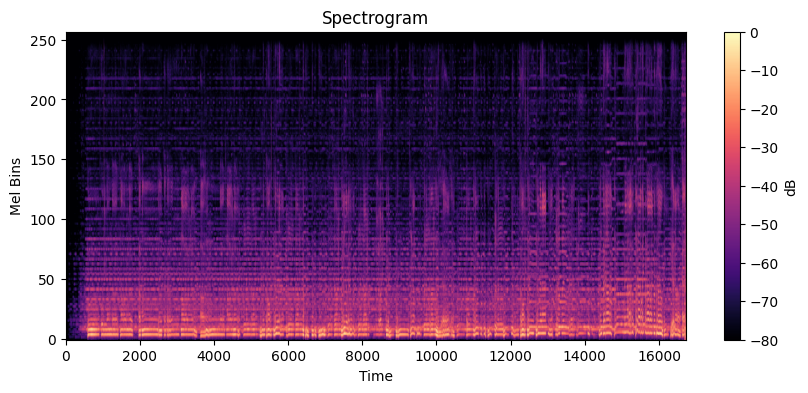

In [16]:
import numpy as np
import matplotlib.pyplot as plt

feat = np.load("/kaggle/working/features_with_labels/spectrogram/0000_spectrogram.npy")

plt.figure(figsize=(10,4))
plt.imshow(feat, aspect="auto", origin="lower", cmap="magma")
plt.colorbar(label="dB")
plt.xlabel("Time")
plt.ylabel("Mel Bins")
plt.title("Spectrogram")
plt.show()

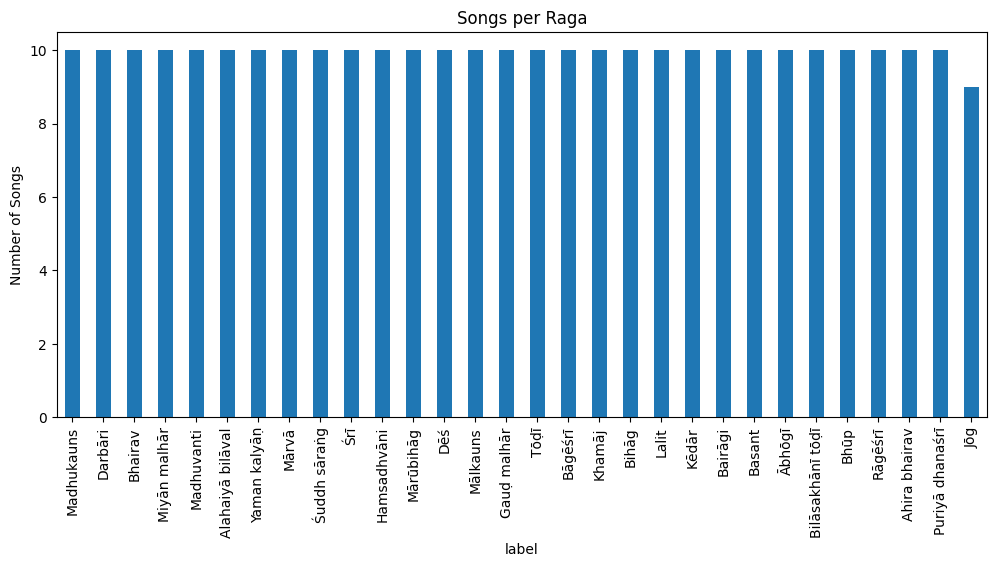

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

manifest = pd.read_csv("/kaggle/working/features_with_labels/spectrogram_manifest.csv")

counts = manifest["label"].value_counts()

plt.figure(figsize=(12,5))
counts.plot(kind="bar")
plt.ylabel("Number of Songs")
plt.title("Songs per Raga")
plt.xticks(rotation=90)
plt.show()

In [22]:
import os
import numpy as np

feat_dir = "/kaggle/working/features_with_labels/spectrogram"

for file in sorted(os.listdir(feat_dir))[:5]:
    feat = np.load(os.path.join(feat_dir, file))
    print(file, feat.shape, feat.dtype)

0000_spectrogram.npy (257, 16720) float16
0001_spectrogram.npy (257, 49633) float16
0002_spectrogram.npy (257, 122673) float16
0004_spectrogram.npy (257, 146184) float16
0005_spectrogram.npy (257, 29144) float16
